# ROW supplement: fixed S = 2 / 3 / 4 identity slots x {Transformer AR, Looped AR} = 6 runs

Standalone supplement to notebook 18. It does NOT touch notebook 18's 26-job queue or its results.

| condition | S | train k | held-out test | test records / model |
|---|---|---|---|---|
| identity_s2_train02_row | 2 | 0,2 | A/B/C at both slots | 16,000 |
| identity_s3_train023_row | 3 | 0,2,3 | A/B/C at all 3 slots | 46,000 |
| identity_s4_train0234_row | 4 | 0,2,3,4 | A/B/C at all 4 slots | 130,000 |

**Format.** Real `<ROW>` tokens between the rows of the input AND output grids, visible `<identity>` fillers, and
learned positions. Sequences are 89 / 90 / 91 tokens.

**Same machinery as notebook 18.** Serializer, vocabulary, model config, the common fresh initialization, the
42-target loss, digit-CE selection, and free-running unrepaired scoring.

**Pairing.**
* The logical stream equals the main S5 / variable stream at the same support.
* Placements and test manifests equal notebook 16's S=2/3/4 no-ROW runs.

**Comparisons.** Comparisons with notebook 18 and notebook 16 are read-only, and only use completed artifacts. Missing
ones show as pending.

**Send back `AR_Row_Slots234_Review.ipynb`** (printed and downloaded by the last cell). One seed: descriptive only.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 6b8fa76bf50919b85a53da2aafa4c9152ffc96ae


In [2]:
# --- CONFIGURATION ------------------------------------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")      # "full" | "smoke" (tiny CPU check, separate root, NOT results)
SEED = 42
SUPPLEMENT_CONDITIONS = ["identity_s2_train02_row", "identity_s3_train023_row", "identity_s4_train0234_row"]
MODEL_IDS = ["transformer_ar", "looped_transformer_ar"]
RUN_STAGES = ["train", "evaluate", "analyze"]
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
DTYPE = "auto"
EVAL_CHUNK_GRIDS = 100
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import json, pathlib
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import rowsep as RS, rowsep_reports as RR, rowsep_slots as SP
from decompositionality.config import make_experiment_config
JOBS = SP.jobs(SUPPLEMENT_CONDITIONS, MODEL_IDS)
OUTPUT_ROOT = RR.family_root(RESULTS_ROOT, MODE, SP.SUBDIR)
MAIN_ROOT = RR.family_root(RESULTS_ROOT, MODE)          # notebook-18 root: READ-ONLY
_c = make_experiment_config(JOBS[0][0], MODE, str(pathlib.Path(RESULTS_ROOT) / SP.SUBDIR), MODEL_IDS, seed=SEED)
print("resolved recipe:", _c.train.semantic_dict())
print(f"{len(JOBS)} supplement jobs:", JOBS)
print("output ->", OUTPUT_ROOT, "| main suite (read-only) ->", MAIN_ROOT)
if MODE == "smoke":
    print("*** SMOKE MODE - NOT results ***")


Mounted at /content/drive
resolved recipe: {'seed': 42, 'optimizer_steps': 5000, 'effective_batch_size': 256, 'lr': 0.0003, 'min_lr': 3e-05, 'weight_decay': 0.01, 'betas': [0.9, 0.95], 'warmup_steps': 250, 'grad_clip': 1.0, 'val_every': 250}
6 supplement jobs: [('identity_s2_train02_row', 'transformer_ar'), ('identity_s2_train02_row', 'looped_transformer_ar'), ('identity_s3_train023_row', 'transformer_ar'), ('identity_s3_train023_row', 'looped_transformer_ar'), ('identity_s4_train0234_row', 'transformer_ar'), ('identity_s4_train0234_row', 'looped_transformer_ar')]
output -> /content/drive/MyDrive/decompositionality_results/ar_row_slots234_supplement_v1 | main suite (read-only) -> /content/drive/MyDrive/decompositionality_results/ar_row_separators_13conditions_v2


In [3]:
# --- Preflight (stop on failure): layouts, counts, stream / placement / init matching -------------------------------
AUD = OUTPUT_ROOT / "audits" / f"seed_{SEED}"; AUD.mkdir(parents=True, exist_ok=True)
pf, ini = SP.preflight(SEED, main_root=MAIN_ROOT)
lay = RR.layout_audit()
for name, df in (("preflight", pf), ("initialization", ini), ("layout", lay)):
    df.to_csv(AUD / f"{name}.csv", index=False); print(f"\n[{name}]"); display(df)



[preflight]


,condition,S,train_k,seq_len,OUTPUT,EOS,per_k_training_records,no-I training records (k=S),val_records,test_records_per_model,singleton_records,same logical stream as main S5 & variable (same support),same logical stream + placements as notebook-16 no-ROW
0,identity_s2_train02_row,2,"[0, 2]",89,46,88,"{0: 640000, 2: 640000}",640000,600,16000,6000,True,True
1,identity_s3_train023_row,3,"[0, 2, 3]",90,47,89,"{0: 426667, 2: 426667, 3: 426666}",426666,900,46000,9000,True,True
2,identity_s4_train0234_row,4,"[0, 2, 3, 4]",91,48,90,"{0: 320000, 2: 320000, 3: 320000, 4: 320000}",320000,1200,130000,12000,True,True



[initialization]


,model,full_init_sha,legacy_shared_sha,vocab,pos_table,main_suite_recorded_sha,matches_main_suite
0,transformer_ar,5b7b3a2b23b17e06,7df62756243c93c5,21,"(93, 384)",5b7b3a2b23b17e06,True
1,looped_transformer_ar,4cceb5b8be3972b8,f4e8524e4616aa1d,21,"(93, 384)",4cceb5b8be3972b8,True



[layout]


,m,length,OUTPUT,prefix_len,first_output_digit,output_ROW,EOS,ROW_per_grid,positions,ROW coords
0,0,87,44,45,45,"[51, 58, 65, 72, 79]",86,5,dense 0..86,NO_COORD (structural); grid segment
1,1,88,45,46,46,"[52, 59, 66, 73, 80]",87,5,dense 0..87,NO_COORD (structural); grid segment
2,2,89,46,47,47,"[53, 60, 67, 74, 81]",88,5,dense 0..88,NO_COORD (structural); grid segment
3,3,90,47,48,48,"[54, 61, 68, 75, 82]",89,5,dense 0..89,NO_COORD (structural); grid segment
4,4,91,48,49,49,"[55, 62, 69, 76, 83]",90,5,dense 0..90,NO_COORD (structural); grid segment
5,5,92,49,50,50,"[56, 63, 70, 77, 84]",91,5,dense 0..91,NO_COORD (structural); grid segment
6,6,93,50,51,51,"[57, 64, 71, 78, 85]",92,5,dense 0..92,NO_COORD (structural); grid segment


In [4]:
# --- Sequential six-job driver (resumable; one model on the GPU at a time) ------------------------------------------
status = RR.run_queue(RESULTS_ROOT, MODE, SEED, JOBS, RUN_STAGES, repo_dir=str(REPO_DIR), chunk_grids=EVAL_CHUNK_GRIDS,
                      device=DEVICE, dtype=DTYPE, subdir=SP.SUBDIR, universe=SP.jobs())
display(status)


queue (6 jobs): identity_s2_train02_row/TF-AR -> identity_s2_train02_row/Looped-AR -> identity_s3_train023_row/TF-AR -> identity_s3_train023_row/Looped-AR -> identity_s4_train0234_row/TF-AR -> identity_s4_train0234_row/Looped-AR | stages ['train', 'evaluate', 'analyze']
[identity_s2_train02_row] fixed_short | train k=[0, 2] | val 600 | test 16,000 | manifests bdf24c327a65

=== identity_s2_train02_row / transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,707,861 params | device NVIDIA A100-SXM4-40GB | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 0.6902 (best) | subset(64) exact 0.547 cell 0.739
  step 275/5000 loss 0.5056 lr 3.00e-04 | 11.87 steps/s, 3039 ex/s | ETA 6.6 min
  [val @ 500] cell CE 0.0184 (best) | subset(64) exact 0.781 cell 0.993
  step 525/5000 loss 0.0086 lr 2.98e-04 | 11.95 steps/s, 3059 ex/s | ETA 6.2 min
  [val @ 750] cell CE 0.0025 (best) | subset(64) exact 0.953 cell 0.999
  step 775/5000 loss 0.0006 lr 2.92e-04 | 12.07 s

,condition,group,model,selected,train,evaluate,analyze,complete,selected_step,records
0,identity_s2_train02_row,fixed_short,transformer_ar,True,done,done,done,True,5000,16000
1,identity_s2_train02_row,fixed_short,looped_transformer_ar,True,done,done,done,True,5000,16000
2,identity_s3_train023_row,fixed_short,transformer_ar,True,done,done,done,True,5000,46000
3,identity_s3_train023_row,fixed_short,looped_transformer_ar,True,done,done,done,True,5000,46000
4,identity_s4_train0234_row,fixed_short,transformer_ar,True,done,done,done,True,5000,130000
5,identity_s4_train0234_row,fixed_short,looped_transformer_ar,True,done,done,done,True,5000,130000


# ROW supplement: fixed S=2/3/4 x 2 AR models (row-slots234-supplement-v1, seed 42)
6/6 jobs complete — **ALL SIX COMPLETE**


### Status of the six supplement jobs


,condition,group,model,selected,train,evaluate,analyze,complete,selected_step,records
0,identity_s2_train02_row,fixed_short,transformer_ar,True,done,done,done,True,5000,16000
1,identity_s2_train02_row,fixed_short,looped_transformer_ar,True,done,done,done,True,5000,16000
2,identity_s3_train023_row,fixed_short,transformer_ar,True,done,done,done,True,5000,46000
3,identity_s3_train023_row,fixed_short,looped_transformer_ar,True,done,done,done,True,5000,46000
4,identity_s4_train0234_row,fixed_short,transformer_ar,True,done,done,done,True,5000,130000
5,identity_s4_train0234_row,fixed_short,looped_transformer_ar,True,done,done,done,True,5000,130000



### Training / validation curves


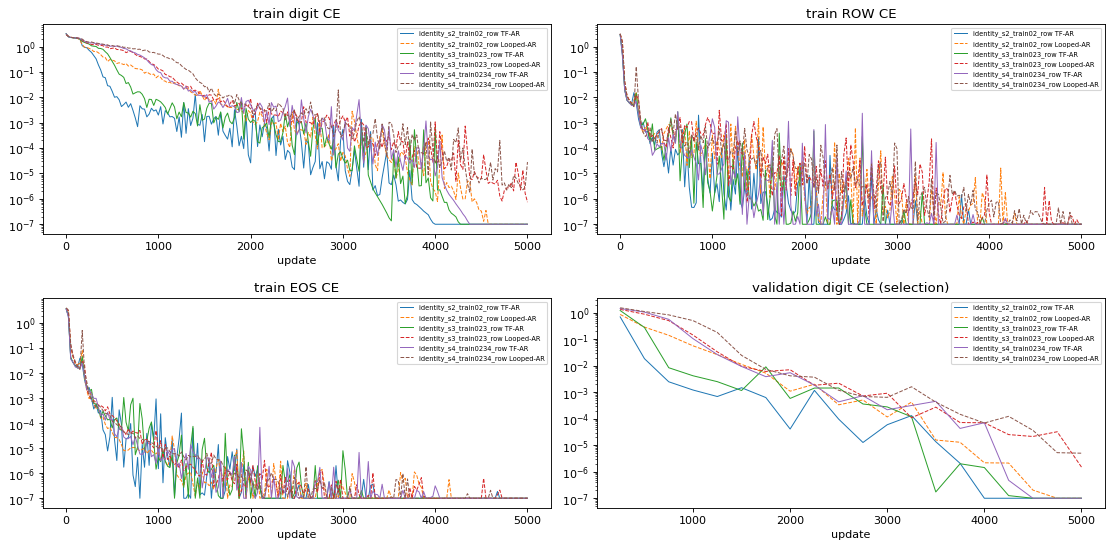


### Accuracy by k (exact / cell / ROW / EOS / strict)


,condition,model,k,support,exact_correct,n,exact_acc,cell_acc,row_token_acc,all5_row_acc,eos_acc,premature_eos_rate,strict_acc,invalid_digit_rate
0,identity_s2_train02_row,transformer_ar,0,train-supported,1000.0,1000.0,1.000000,1.000000,1.0,1.0,1.0,0.0,1.000000,0.000000
1,identity_s2_train02_row,transformer_ar,1,HELD OUT,0.0,6000.0,0.000000,0.099421,1.0,1.0,1.0,0.0,0.000000,0.000000
2,identity_s2_train02_row,transformer_ar,2,train-supported,9000.0,9000.0,1.000000,1.000000,1.0,1.0,1.0,0.0,1.000000,0.000000
3,identity_s2_train02_row,looped_transformer_ar,0,train-supported,1000.0,1000.0,1.000000,1.000000,1.0,1.0,1.0,0.0,1.000000,0.000000
4,identity_s2_train02_row,looped_transformer_ar,1,HELD OUT,0.0,6000.0,0.000000,0.102444,1.0,1.0,1.0,0.0,0.000000,0.000000
5,identity_s2_train02_row,looped_transformer_ar,2,train-supported,9000.0,9000.0,1.000000,1.000000,1.0,1.0,1.0,0.0,1.000000,0.000000
6,identity_s3_train023_row,transformer_ar,0,train-supported,1000.0,1000.0,1.000000,1.000000,1.0,1.0,1.0,0.0,1.000000,0.000000
7,identity_s3_train023_row,transformer_ar,1,HELD OUT,0.0,9000.0,0.000000,0.378889,1.0,1.0,1.0,0.0,0.000000,0.000000
8,identity_s3_train023_row,transformer_ar,2,train-supported,9000.0,9000.0,1.000000,1.000000,1.0,1.0,1.0,0.0,1.000000,0.000000
9,identity_s3_train023_row,transformer_ar,3,train-supported,27000.0,27000.0,1.000000,1.000000,1.0,1.0,1.0,0.0,1.000000,0.000000



### Singletons by operation x slot (every slot)


,condition,model,word,position,exact_correct,n,exact_acc,cell_acc,row_token_acc,all5_row_acc,eos_acc,premature_eos_rate,strict_acc,invalid_digit_rate
0,identity_s2_train02_row,transformer_ar,A,1,0.0,1000.0,0.0,0.099000,1.0,1.0,1.0,0.0,0.0,0.000
1,identity_s2_train02_row,transformer_ar,A,2,0.0,1000.0,0.0,0.099306,1.0,1.0,1.0,0.0,0.0,0.000
2,identity_s2_train02_row,transformer_ar,B,1,0.0,1000.0,0.0,0.101556,1.0,1.0,1.0,0.0,0.0,0.000
3,identity_s2_train02_row,transformer_ar,B,2,0.0,1000.0,0.0,0.098444,1.0,1.0,1.0,0.0,0.0,0.000
4,identity_s2_train02_row,transformer_ar,C,1,0.0,1000.0,0.0,0.099111,1.0,1.0,1.0,0.0,0.0,0.000
5,identity_s2_train02_row,transformer_ar,C,2,0.0,1000.0,0.0,0.099111,1.0,1.0,1.0,0.0,0.0,0.000
6,identity_s2_train02_row,looped_transformer_ar,A,1,0.0,1000.0,0.0,0.100000,1.0,1.0,1.0,0.0,0.0,0.000
7,identity_s2_train02_row,looped_transformer_ar,A,2,0.0,1000.0,0.0,0.099417,1.0,1.0,1.0,0.0,0.0,0.000
8,identity_s2_train02_row,looped_transformer_ar,B,1,0.0,1000.0,0.0,0.101500,1.0,1.0,1.0,0.0,0.0,0.000
9,identity_s2_train02_row,looped_transformer_ar,B,2,0.0,1000.0,0.0,0.115528,1.0,1.0,1.0,0.0,0.0,0.000



### Singleton outcomes (exact / identity copy / other legal / non-legal / invalid)


,condition,model,word,n,exact_correct,identity_copy,other_legal_transform,nonlegal_valid_grid,invalid_digit_output,extra_C_residual
0,identity_s2_train02_row,transformer_ar,A,2000,0,0,1951,49,0,1951
1,identity_s2_train02_row,transformer_ar,B,2000,0,0,900,1100,0,900
2,identity_s2_train02_row,transformer_ar,C,2000,0,2000,0,0,0,2000
3,identity_s2_train02_row,looped_transformer_ar,A,2000,0,0,904,1096,0,904
4,identity_s2_train02_row,looped_transformer_ar,B,2000,0,0,69,1931,0,69
5,identity_s2_train02_row,looped_transformer_ar,C,2000,0,2000,0,0,0,2000
6,identity_s3_train023_row,transformer_ar,A,3000,0,0,0,3000,0,0
7,identity_s3_train023_row,transformer_ar,B,3000,0,0,0,3000,0,0
8,identity_s3_train023_row,transformer_ar,C,3000,0,3000,0,0,0,3000
9,identity_s3_train023_row,looped_transformer_ar,A,3000,0,0,1716,1284,0,985


... (5 outputs left out)

,condition,model,op,grids_identical_prediction_all_slots,grids_all_slots_correct,grids_all_slots_wrong
0,identity_s2_train02_row,transformer_ar,A,0.000,0.0,1.0
1,identity_s2_train02_row,transformer_ar,B,0.000,0.0,1.0
2,identity_s2_train02_row,transformer_ar,C,1.000,0.0,1.0
3,identity_s2_train02_row,looped_transformer_ar,A,0.000,0.0,1.0
4,identity_s2_train02_row,looped_transformer_ar,B,0.000,0.0,1.0
5,identity_s2_train02_row,looped_transformer_ar,C,1.000,0.0,1.0
6,identity_s3_train023_row,transformer_ar,A,0.000,0.0,1.0
7,identity_s3_train023_row,transformer_ar,B,0.000,0.0,1.0
8,identity_s3_train023_row,transformer_ar,C,1.000,0.0,1.0
9,identity_s3_train023_row,looped_transformer_ar,A,0.000,0.0,1.0



### Same-target pairs (A~ACC, B~BCC, C~CCC within each manifest)


,condition,model,singleton,composite,status,composite_in_training,grids,composite_correct,grids comp correct & singleton wrong at all slots,grids comp correct & singleton correct at all slots,grids comp wrong & singleton correct at all slots
0,identity_s2_train02_row,transformer_ar,A,ACC,unavailable (not in this condition's manifest),NaN,NaN,NaN,NaN,NaN,NaN
1,identity_s2_train02_row,transformer_ar,B,BCC,unavailable (not in this condition's manifest),NaN,NaN,NaN,NaN,NaN,NaN
2,identity_s2_train02_row,transformer_ar,C,CCC,unavailable (not in this condition's manifest),NaN,NaN,NaN,NaN,NaN,NaN
3,identity_s2_train02_row,transformer_ar,C,CCCCC,unavailable (not in this condition's manifest),NaN,NaN,NaN,NaN,NaN,NaN
4,identity_s2_train02_row,looped_transformer_ar,A,ACC,unavailable (not in this condition's manifest),NaN,NaN,NaN,NaN,NaN,NaN
5,identity_s2_train02_row,looped_transformer_ar,B,BCC,unavailable (not in this condition's manifest),NaN,NaN,NaN,NaN,NaN,NaN
6,identity_s2_train02_row,looped_transformer_ar,C,CCC,unavailable (not in this condition's manifest),NaN,NaN,NaN,NaN,NaN,NaN
7,identity_s2_train02_row,looped_transformer_ar,C,CCCCC,unavailable (not in this condition's manifest),NaN,NaN,NaN,NaN,NaN,NaN
8,identity_s3_train023_row,transformer_ar,A,ACC,available,True,1000.0,1000.0,1000.0,0.0,0.0
9,identity_s3_train023_row,transformer_ar,B,BCC,available,True,1000.0,1000.0,1000.0,0.0,0.0



### Singleton 6x6 cell error heatmaps


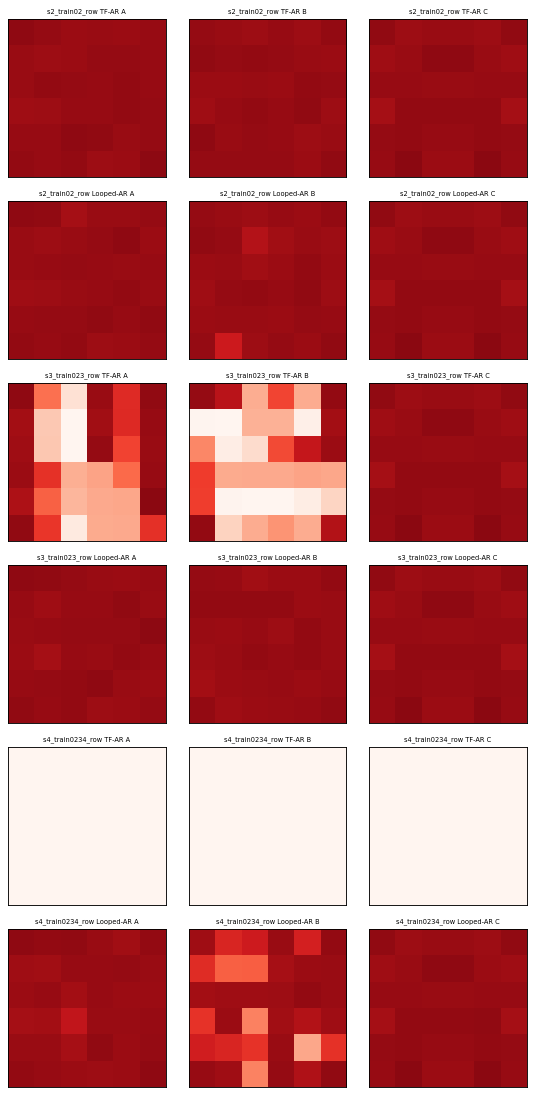


### Comparison 1 (read-only): new short-slot ROW vs main ROW suite at the same support


,new,reference,reference_kind,model,matching,op,status,grids,reference_mean,new_mean,improved,tied,worsened
0,identity_s2_train02_row,identity_s5_train02,main ROW S5,transformer_ar,same logical stream + common init (by construc...,A,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0
1,identity_s2_train02_row,identity_s5_train02,main ROW S5,transformer_ar,same logical stream + common init (by construc...,B,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0
2,identity_s2_train02_row,identity_s5_train02,main ROW S5,transformer_ar,same logical stream + common init (by construc...,C,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0
3,identity_s2_train02_row,variable_train02,main ROW variable,transformer_ar,same logical stream + common init (by construc...,A,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0
4,identity_s2_train02_row,variable_train02,main ROW variable,transformer_ar,same logical stream + common init (by construc...,B,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0
5,identity_s2_train02_row,variable_train02,main ROW variable,transformer_ar,same logical stream + common init (by construc...,C,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0
6,identity_s2_train02_row,identity_s5_train02,main ROW S5,looped_transformer_ar,same logical stream + common init (by construc...,A,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0
7,identity_s2_train02_row,identity_s5_train02,main ROW S5,looped_transformer_ar,same logical stream + common init (by construc...,B,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0
8,identity_s2_train02_row,identity_s5_train02,main ROW S5,looped_transformer_ar,same logical stream + common init (by construc...,C,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0
9,identity_s2_train02_row,variable_train02,main ROW variable,looped_transformer_ar,same logical stream + common init (by construc...,A,"paired by (op, grid hash); mean over each cond...",1000,0.0000,0.0,0,1000,0



### Comparison 2 (read-only): new ROW vs historical no-ROW (notebook 16) at the same S / support


,new,historical_noROW,model,matching,op,status,grids,noROW_mean,ROW_mean,improved,tied,worsened
0,identity_s2_train02_row,S2/train02/transformer_ar,transformer_ar,"same logical stream, placements, test manifest...",A,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0
1,identity_s2_train02_row,S2/train02/transformer_ar,transformer_ar,"same logical stream, placements, test manifest...",B,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0
2,identity_s2_train02_row,S2/train02/transformer_ar,transformer_ar,"same logical stream, placements, test manifest...",C,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0
3,identity_s2_train02_row,S2/train02/looped_transformer_ar,looped_transformer_ar,"same logical stream, placements, test manifest...",A,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0
4,identity_s2_train02_row,S2/train02/looped_transformer_ar,looped_transformer_ar,"same logical stream, placements, test manifest...",B,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0
5,identity_s2_train02_row,S2/train02/looped_transformer_ar,looped_transformer_ar,"same logical stream, placements, test manifest...",C,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0
6,identity_s3_train023_row,S3/train023/transformer_ar,transformer_ar,"same logical stream, placements, test manifest...",A,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0
7,identity_s3_train023_row,S3/train023/transformer_ar,transformer_ar,"same logical stream, placements, test manifest...",B,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0
8,identity_s3_train023_row,S3/train023/transformer_ar,transformer_ar,"same logical stream, placements, test manifest...",C,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0
9,identity_s3_train023_row,S3/train023/looped_transformer_ar,looped_transformer_ar,"same logical stream, placements, test manifest...",A,"paired by (op, grid hash)",1000,0.0,0.0,0,1000,0


**Interpretation limits.**
* All three supplement conditions train some zero-I examples (k=S), unlike S5/train02/023/0234.
* Changing S also changes sequence length, positions, layouts, filler count and compute: this is not a pure I-presence intervention.
* S2/train02 trains only even operation counts, so the even-count ambiguity remains.
* One seed: descriptive only.


### Audit: preflight


... (3 outputs left out)


### Audit: layout


,m,length,OUTPUT,prefix_len,first_output_digit,output_ROW,EOS,ROW_per_grid,positions,ROW coords
0,0,87,44,45,45,"[51, 58, 65, 72, 79]",86,5,dense 0..86,NO_COORD (structural); grid segment
1,1,88,45,46,46,"[52, 59, 66, 73, 80]",87,5,dense 0..87,NO_COORD (structural); grid segment
2,2,89,46,47,47,"[53, 60, 67, 74, 81]",88,5,dense 0..88,NO_COORD (structural); grid segment
3,3,90,47,48,48,"[54, 61, 68, 75, 82]",89,5,dense 0..89,NO_COORD (structural); grid segment
4,4,91,48,49,49,"[55, 62, 69, 76, 83]",90,5,dense 0..90,NO_COORD (structural); grid segment
5,5,92,49,50,50,"[56, 63, 70, 77, 84]",91,5,dense 0..91,NO_COORD (structural); grid segment
6,6,93,50,51,51,"[57, 64, 71, 78, 85]",92,5,dense 0..92,NO_COORD (structural); grid segment



### Resources and provenance


,condition,model,params,seq_len,train_min,eval_min,best_step,peak_gb,hardware,repo_commit
0,identity_s2_train02_row,transformer_ar,10707861,89,6.864526,0.313739,5000,2.145393,NVIDIA A100-SXM4-40GB,6b8fa76bf50919b85a53da2aafa4c9152ffc96ae
1,identity_s2_train02_row,looped_transformer_ar,1835541,89,6.319529,0.263871,5000,2.092688,NVIDIA A100-SXM4-40GB,6b8fa76bf50919b85a53da2aafa4c9152ffc96ae
2,identity_s3_train023_row,transformer_ar,10707861,90,8.217800,0.743030,5000,2.146503,NVIDIA A100-SXM4-40GB,6b8fa76bf50919b85a53da2aafa4c9152ffc96ae
3,identity_s3_train023_row,looped_transformer_ar,1835541,90,7.368168,0.694667,5000,2.092688,NVIDIA A100-SXM4-40GB,6b8fa76bf50919b85a53da2aafa4c9152ffc96ae
4,identity_s4_train0234_row,transformer_ar,10707861,91,9.689185,1.975485,5000,2.146503,NVIDIA A100-SXM4-40GB,6b8fa76bf50919b85a53da2aafa4c9152ffc96ae
5,identity_s4_train0234_row,looped_transformer_ar,1835541,91,8.689154,1.932708,5000,2.092688,NVIDIA A100-SXM4-40GB,6b8fa76bf50919b85a53da2aafa4c9152ffc96ae


In [ ]:
# --- Report + read-only comparisons + review export (rerunnable alone; never trains) ---------------------------
rp = SP.report(RESULTS_ROOT, MODE, SEED, JOBS)
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB:
    from google.colab import files
    files.download(str(rp))
